In [1]:
#importing necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
#importing the ddataset
student_scores = pd.read_csv("student-scores.csv")
student_scores.head()

,id,first_name,last_name,email,gender,part_time_job,absence_days,extracurricular_activities,weekly_self_study_hours,career_aspiration,math_score,history_score,physics_score,chemistry_score,biology_score,english_score,geography_score
0,1,Paul,Casey,paul.casey.1@gslingacademy.com,male,False,3,False,27,Lawyer,73,81,93,97,63,80,87
1,2,Danielle,Sandoval,danielle.sandoval.2@gslingacademy.com,female,False,2,False,47,Doctor,90,86,96,100,90,88,90
2,3,Tina,Andrews,tina.andrews.3@gslingacademy.com,female,False,9,True,13,Government Officer,81,97,95,96,65,77,94
3,4,Tara,Clark,tara.clark.4@gslingacademy.com,female,False,5,False,3,Artist,71,74,88,80,89,63,86
4,5,Anthony,Campos,anthony.campos.5@gslingacademy.com,male,False,5,False,10,Unknown,84,77,65,65,80,74,76


# Data Preprocessing & Cleaning


In [3]:
#checking the info summary of the dataset
student_scores.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   id                          2000 non-null   int64 
 1   first_name                  2000 non-null   object
 2   last_name                   2000 non-null   object
 3   email                       2000 non-null   object
 4   gender                      2000 non-null   object
 5   part_time_job               2000 non-null   bool  
 6   absence_days                2000 non-null   int64 
 7   extracurricular_activities  2000 non-null   bool  
 8   weekly_self_study_hours     2000 non-null   int64 
 9   career_aspiration           2000 non-null   object
 10  math_score                  2000 non-null   int64 
 11  history_score               2000 non-null   int64 
 12  physics_score               2000 non-null   int64 
 13  chemistry_score             2000 non-null   int6

In [4]:
#checking the summary statistics of the dataset
student_scores.describe()

,id,absence_days,weekly_self_study_hours,math_score,history_score,physics_score,chemistry_score,biology_score,english_score,geography_score
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000
mean,1000.500000,3.665500,17.755500,83.452000,80.332000,81.336500,79.995000,79.58150,81.277500,80.888000
std,577.494589,2.629271,12.129604,13.224906,12.736046,12.539453,12.777895,13.72219,12.027087,11.637705
min,1.000000,0.000000,0.000000,40.000000,50.000000,50.000000,50.000000,30.00000,50.000000,60.000000
25%,500.750000,2.000000,5.000000,77.000000,69.750000,71.000000,69.000000,69.00000,72.000000,71.000000
50%,1000.500000,3.000000,18.000000,87.000000,82.000000,83.000000,81.000000,81.00000,83.000000,81.000000
75%,1500.250000,5.000000,28.000000,93.000000,91.000000,92.000000,91.000000,91.00000,91.000000,91.000000
max,2000.000000,10.000000,50.000000,100.000000,100.000000,100.000000,100.000000,100.00000,99.000000,100.000000


In [5]:
#30-39, 40-49, 50-59, 60-69, 70-79, 80-89, 90-100

In [6]:
#checking for missing values
student_scores.isnull().sum()

id                            0
first_name                    0
last_name                     0
email                         0
gender                        0
part_time_job                 0
absence_days                  0
extracurricular_activities    0
weekly_self_study_hours       0
career_aspiration             0
math_score                    0
history_score                 0
physics_score                 0
chemistry_score               0
biology_score                 0
english_score                 0
geography_score               0
dtype: int64

The dataset has no missing value(s)

In [7]:
#checking for duplicate
student_scores.duplicated().sum()

0

The dataset has no dulicate

# Exploratory Data Analysis (EDA)


In [8]:
#checking for the number of unique gender
student_scores["gender"].nunique()

2

In [9]:
#count each unique gender
student_scores["gender"].value_counts()

gender
female    1002
male       998
Name: count, dtype: int64

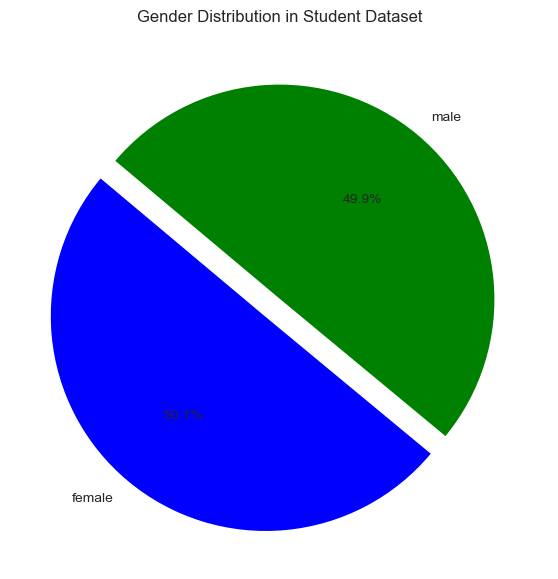

In [56]:

# Count occurrences of each gender
gender_counts = student_scores["gender"].value_counts()

# Identify the gender with the highest count
highest_gender = gender_counts.idxmax()

# Create explode list (explode the highest gender)
explode = [0.1 if gender == highest_gender else 0 for gender in gender_counts.index]

# Plot pie chart
plt.figure(figsize=(7, 7))
plt.pie(gender_counts, labels=gender_counts.index, autopct="%1.1f%%", 
        explode=explode, colors=["blue", "green", "purple"], startangle=140)

# Title
plt.title("Gender Distribution in Student Dataset")

# Save the plot in high quality (PNG format with 300 DPI)
plt.savefig("gender.png", format="png", dpi=300, bbox_inches="tight")

# Show plot
plt.show()



In [10]:
#counting the number of student with part time job and those that do not
student_scores["part_time_job"].value_counts()

part_time_job
False    1684
True      316
Name: count, dtype: int64

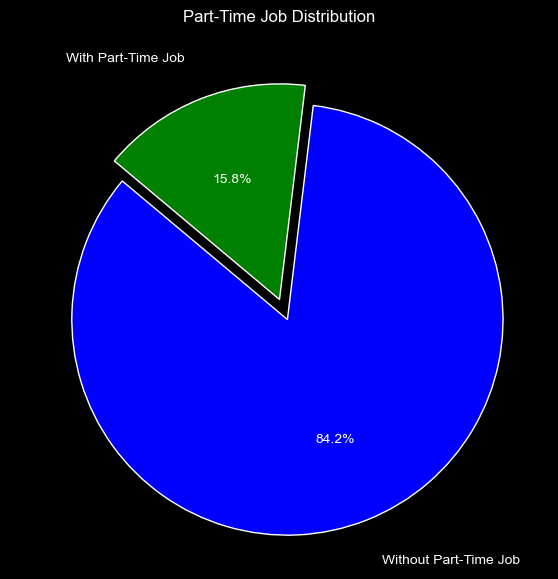

In [59]:



import matplotlib.pyplot as plt

# Example of part_time_job data
part_time_counts = {
    "False": 1684,
    "True": 316
}

# Create explode list (explode the 'True' part-time job)
highest_part_time = max(part_time_counts, key=part_time_counts.get)
explode = [0.1 if key == highest_part_time else 0 for key in part_time_counts]

# Define the labels with more descriptive names
labels = ["Without Part-Time Job", "With Part-Time Job"]

# Plot pie chart with a dark background
plt.figure(figsize=(7, 7), facecolor='black')  # Set background color to black
plt.pie(part_time_counts.values(), labels=labels, autopct="%1.1f%%", 
        explode=explode, colors=["blue", "green"], startangle=140, 
        textprops={'color': 'white'}, labeldistance=1.2)

# Title with white color
plt.title("Part-Time Job Distribution", color='white')

# Save the plot in high quality (PNG format with 300 DPI)
plt.savefig("part_time_job_distribution.png", format="png", dpi=300, bbox_inches="tight")

# Show plot
plt.show()




In [12]:
#checking if the student email is a unique identifier
student_scores["email"].nunique()

2000

In [13]:
student_scores["absence_days"].value_counts()

absence_days
2     344
1     341
3     336
4     199
5     196
6     136
7     130
0     123
10     88
9      56
8      51
Name: count, dtype: int64

## Feature Engineering

#0-39, 40-49, 50-59, 60-69, 70-79, 80-89, 90-100

In [15]:
#Creating additonal columns "average_score" and "student_grades"

# Define grade bins and labels
bins = [0, 39, 49, 59, 69, 79, 89, 100]  
labels = ["F", "E", "C", "B", "A", "AA", "AAA"]  

# Calculate the average score across all subjects
student_scores["average_score"] = student_scores[
    ["math_score", "history_score", "physics_score", "chemistry_score", "biology_score", "english_score", "geography_score"]
].mean(axis=1)

# Apply grading based on the average score
student_scores["student_grades"] = pd.cut(student_scores["average_score"], bins=bins, labels=labels, right=True)

# View the updated DataFrame
student_scores.head()

,id,first_name,last_name,email,gender,part_time_job,absence_days,extracurricular_activities,weekly_self_study_hours,career_aspiration,math_score,history_score,physics_score,chemistry_score,biology_score,english_score,geography_score,average_score,student_grades
0,1,Paul,Casey,paul.casey.1@gslingacademy.com,male,False,3,False,27,Lawyer,73,81,93,97,63,80,87,82.000000,AA
1,2,Danielle,Sandoval,danielle.sandoval.2@gslingacademy.com,female,False,2,False,47,Doctor,90,86,96,100,90,88,90,91.428571,AAA
2,3,Tina,Andrews,tina.andrews.3@gslingacademy.com,female,False,9,True,13,Government Officer,81,97,95,96,65,77,94,86.428571,AA
3,4,Tara,Clark,tara.clark.4@gslingacademy.com,female,False,5,False,3,Artist,71,74,88,80,89,63,86,78.714286,A
4,5,Anthony,Campos,anthony.campos.5@gslingacademy.com,male,False,5,False,10,Unknown,84,77,65,65,80,74,76,74.428571,A


## Analysis

## 1. How do weekly self-study hours impact students’ scores across different subjects?


In [94]:
#Calling uo the first few rows
student_scores.head()

,id,first_name,last_name,email,gender,part_time_job,absence_days,extracurricular_activities,weekly_self_study_hours,career_aspiration,math_score,history_score,physics_score,chemistry_score,biology_score,english_score,geography_score,average_score,student_grades
0,1,Paul,Casey,paul.casey.1@gslingacademy.com,male,False,3,False,27,Lawyer,73,81,93,97,63,80,87,82.000000,AA
1,2,Danielle,Sandoval,danielle.sandoval.2@gslingacademy.com,female,False,2,False,47,Doctor,90,86,96,100,90,88,90,91.428571,AAA
2,3,Tina,Andrews,tina.andrews.3@gslingacademy.com,female,False,9,True,13,Government Officer,81,97,95,96,65,77,94,86.428571,AA
3,4,Tara,Clark,tara.clark.4@gslingacademy.com,female,False,5,False,3,Artist,71,74,88,80,89,63,86,78.714286,A
4,5,Anthony,Campos,anthony.campos.5@gslingacademy.com,male,False,5,False,10,Unknown,84,77,65,65,80,74,76,74.428571,A


In [18]:
#calling up scores of student that self study
student_self_study = student_scores.loc[student_scores["weekly_self_study_hours"] > 0,["email","average_score"]]
student_self_study

,email,average_score
0,paul.casey.1@gslingacademy.com,82.000000
1,danielle.sandoval.2@gslingacademy.com,91.428571
2,tina.andrews.3@gslingacademy.com,86.428571
3,tara.clark.4@gslingacademy.com,78.714286
4,anthony.campos.5@gslingacademy.com,74.428571
...,...,...
1995,alan.reynolds.1996@gslingacademy.com,79.714286
1996,thomas.gilbert.1997@gslingacademy.com,76.285714
1997,madison.cross.1998@gslingacademy.com,82.571429
1998,brittany.compton.1999@gslingacademy.com,80.857143


In [95]:
#defining students with higher grades that self study
higher_achiever = student_self_study[student_self_study["average_score"] > 70]

#defining the percentage of students with higher grades
percentage_higher_achiever = (len (higher_achiever)/len(student_self_study)) * 100

print(f'percentage of student that self study with an average score > 70 : {percentage_higher_achiever:.2f}%')

percentage of student that self study with an average score > 70 : 95.80%


In [20]:
#defining students with lower grades with self study
lower_achiever = student_self_study[student_self_study["average_score"] < 70]

#defining the percentage of students with lower grades
percentage_lower_achiever = (len (lower_achiever)/len(student_self_study)) * 100

print(f'percentage of student that self study with an average score < 70 : {percentage_lower_achiever:.2f}%')

percentage of student that self study with an average score < 70 : 4.04%


In [21]:
#calling up scores of student that do not self study
student_not_self_study = student_scores.loc[student_scores["weekly_self_study_hours"] == 0,["email", "average_score"]]
student_not_self_study

,email,average_score
15,roger.wiley.16@gslingacademy.com,74.714286
52,luke.shannon.53@gslingacademy.com,68.428571
105,cynthia.brown.106@gslingacademy.com,82.857143
114,robert.turner.115@gslingacademy.com,76.000000
133,cory.perez.134@gslingacademy.com,72.142857
...,...,...
1780,jessica.smith.1781@gslingacademy.com,84.857143
1812,brenda.sanders.1813@gslingacademy.com,82.857143
1858,johnny.gomez.1859@gslingacademy.com,72.142857
1894,alexis.byrd.1895@gslingacademy.com,67.571429


In [22]:
#defining students with higher grades without self study
higher_achiever_no_study = student_not_self_study[student_not_self_study["average_score"] > 70]

#defining the percentage of students with higher grades
percentage_higher_achiever_no_study = (len (higher_achiever_no_study)/len(student_not_self_study)) * 100

print(f'percentage of student without self study with an average score > 70 : {percentage_higher_achiever_no_study:.2f}%')

percentage of student without self study with an average score > 70 : 87.14%


In [23]:
#defining students with lower grades without self study
lower_achiever_no_study = student_not_self_study[student_not_self_study["average_score"] < 70]

#defining the percentage of students with higher grades
percentage_lower_achiever_no_study = (len (lower_achiever_no_study)/len(student_not_self_study)) * 100

print(f'percentage of student without self study with an average score < 70 : {percentage_lower_achiever_no_study:.2f}%')

percentage of student without self study with an average score < 70 : 12.86%


from the above average scores of student that self study and those that don't self study, it shows that self study has a great impact in their scores

In [24]:
#checking the impact of the self study hours on each of the subject
student_scores.groupby("weekly_self_study_hours")[["math_score", "history_score", "physics_score", "chemistry_score", 
                                                       "biology_score", "english_score", "geography_score"]].mean()


,math_score,history_score,physics_score,chemistry_score,biology_score,english_score,geography_score
weekly_self_study_hours,,,,,,,
0,75.028571,76.742857,75.885714,76.000000,75.957143,76.271429,78.614286
1,75.426966,74.157303,78.606742,79.404494,76.112360,75.573034,79.662921
2,76.314607,75.314607,78.651685,76.775281,75.325843,76.674157,80.887640
3,73.754902,76.637255,79.000000,78.794118,79.784314,79.696078,78.823529
4,75.833333,75.166667,77.843137,75.215686,76.274510,76.950980,79.980392
5,72.659574,75.606383,80.468085,76.531915,78.117021,75.393617,80.382979
6,79.086957,82.434783,80.782609,80.913043,78.695652,79.391304,80.956522
7,81.272727,78.454545,84.272727,81.318182,79.363636,81.181818,76.227273
8,79.928571,82.428571,79.392857,76.392857,80.785714,77.750000,76.928571


C:\Users\baliq\AppData\Local\Temp\ipykernel_19156\1833068320.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=student_scores["weekly_self_study_hours"],


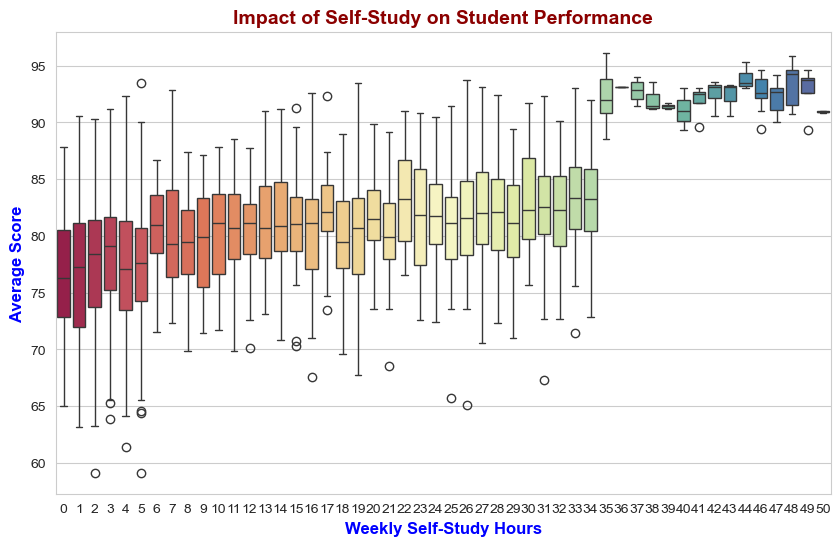

In [49]:
plt.figure(figsize=(10,6))

# Set a colorful theme
sns.set_style("whitegrid")  # Options: "white", "dark", "ticks"
sns.set_palette("deep")   # Options: "deep", "muted", "bright", "pastel", "dark", "colorblind"

# Apply a color mapping to the boxplot
sns.boxplot(x=student_scores["weekly_self_study_hours"], 
            y=student_scores["average_score"], 
            palette="Spectral")  # Options: "viridis", "coolwarm", "Spectral", etc.

plt.xlabel("Weekly Self-Study Hours", fontsize=12, fontweight='bold', color='blue')
plt.ylabel("Average Score", fontsize=12, fontweight='bold', color='blue')
plt.title("Impact of Self-Study on Student Performance", fontsize=14, fontweight='bold', color='darkred')

# Save with high resolution
plt.savefig("study.png", dpi=300, bbox_inches='tight')

plt.show()


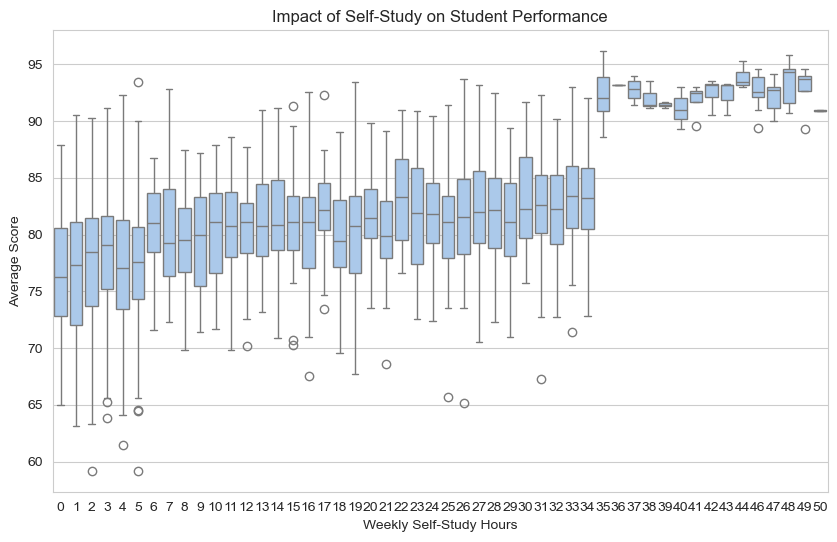

In [26]:
#Visualising the impact of self study on student performance

plt.figure(figsize=(10,6))
sns.boxplot(x=student_scores["weekly_self_study_hours"], y=student_scores["average_score"])
plt.xlabel("Weekly Self-Study Hours")
plt.ylabel("Average Score")
plt.title("Impact of Self-Study on Student Performance")
plt.savefig("study")
plt.show()


Key Observations:
As the weekly self-study hours increase, the average scores tend to rise. This suggests that students who study more tend to perform better.

For lower self-study hours (0-10 hours), scores are widely spread, meaning performance varies significantly.

As self-study hours increase (10-30 hours), the score distribution becomes more stable, with the median score rising.

For very high study hours (35+ hours), scores are more concentrated around high values (85-95), meaning less variation in performance.

While median scores stabilize at 35+ hours, that doesn’t mean extra study is wasted.

Students who struggle with certain subjects may require extra time to catch up and secure better scores.

The graph doesn’t tell us about individual study effectiveness, some students might study longer but inefficiently, while others use their time wisely.

Quality > Quantity, A student studying 20 hours effectively can outperform another who studies 40 hours inefficiently.

In conclusion:

Self-study appears optimal for strong academic performance.

More study generally leads to better performance, but the effect varies across students.

Some students excel with minimal study, while others require more effort to achieve similar results.

Rather than focusing solely on hours, students should identify their most effective study methods to maximize performance.

## 2. Do students with part-time jobs perform differently compared to those without jobs?


In [27]:
student_without_pjobs = student_scores.loc[student_scores["part_time_job"] == False, ["email", "average_score"]]
student_without_pjobs.head()

,email,average_score
0,paul.casey.1@gslingacademy.com,82.000000
1,danielle.sandoval.2@gslingacademy.com,91.428571
2,tina.andrews.3@gslingacademy.com,86.428571
3,tara.clark.4@gslingacademy.com,78.714286
4,anthony.campos.5@gslingacademy.com,74.428571


In [28]:
#defining students with higher grades without part time job
higher_achiever = student_without_pjobs[student_without_pjobs["average_score"] > 70]

#defining the percentage of students with higher grades
percentage_higher_achiever = (len (higher_achiever)/len(student_without_pjobs)) * 100

print(f'percentage of student without part time job with an average score > 70 : {percentage_higher_achiever:.2f}%')

percentage of student without part time job with an average score > 70 : 97.03%


In [29]:
#defining students with lower grades without part time job
lower_achiever = student_without_pjobs[student_without_pjobs["average_score"] < 70]

#defining the percentage of students with higher grades
percentage_lower_achiever = (len (lower_achiever)/len(student_without_pjobs)) * 100

print(f'percentage of student without part time job with an average score < 70 : {percentage_lower_achiever:.2f}%')

percentage of student without part time job with an average score < 70 : 2.85%


In [30]:
student_with_pjobs = student_scores.loc[student_scores["part_time_job"] == True, ["email", "average_score"]]
student_with_pjobs.head()

,email,average_score
7,george.short.8@gslingacademy.com,82.000000
12,patricia.gomez.13@gslingacademy.com,73.714286
20,tim.nichols.21@gslingacademy.com,86.000000
41,jesus.rasmussen.42@gslingacademy.com,66.571429
42,lauren.farmer.43@gslingacademy.com,86.285714


In [31]:
#defining students with higher grades with part time job
higher_achiever = student_with_pjobs[student_with_pjobs["average_score"] > 70]

#defining the percentage of students with higher grades
percentage_higher_achiever = (len (higher_achiever)/len(student_with_pjobs)) * 100

print(f'percentage of student with part time job with an average score > 70 : {percentage_higher_achiever:.2f}%')

percentage of student with part time job with an average score > 70 : 87.34%


In [32]:
#defining students with lower grades with part time job
lower_achiever = student_with_pjobs[student_with_pjobs["average_score"] < 70]

#defining the percentage of students with higher grades
percentage_lower_achiever = (len (lower_achiever)/len(student_with_pjobs)) * 100

print(f'percentage of student with part time job with an average score < 70 : {percentage_lower_achiever:.2f}%')

percentage of student with part time job with an average score < 70 : 12.34%


In [60]:
#checking the mean of the average score for student with and without part time job
avg_score_with_job = student_scores[student_scores["part_time_job"] == True]["average_score"].mean()
avg_score_without_job = student_scores[student_scores["part_time_job"] == False]["average_score"].mean()

print(f"Average Score (With Part-Time Job): {avg_score_with_job:.2f}")
print(f"Average Score (Without Part-Time Job): {avg_score_without_job:.2f}")


Average Score (With Part-Time Job): 78.29
Average Score (Without Part-Time Job): 81.48


C:\Users\baliq\AppData\Local\Temp\ipykernel_19156\2484257244.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="part_time_job", y="average_score", data=student_scores, palette="Set3")


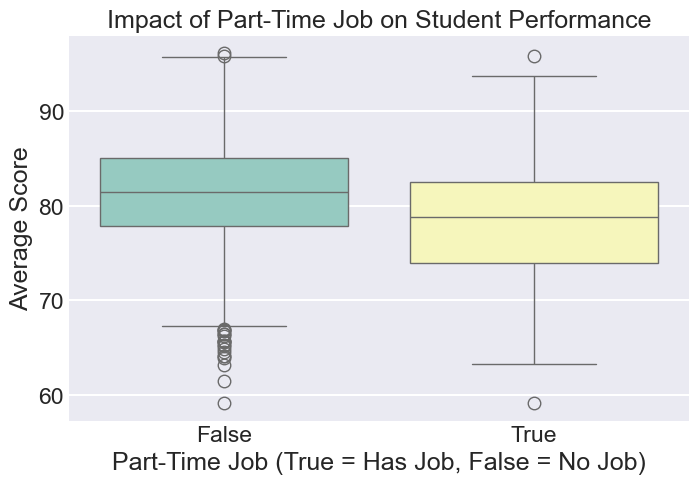

In [96]:
# Assuming student_scores is your DataFrame containing relevant data
plt.figure(figsize=(8, 5))

# Using a colorful palette for the boxplot
sns.boxplot(x="part_time_job", y="average_score", data=student_scores, palette="Set3")

# Adding labels and title
plt.xlabel("Part-Time Job (True = Has Job, False = No Job)")
plt.ylabel("Average Score")
plt.title("Impact of Part-Time Job on Student Performance")

# Saving the plot as a PNG file for export
plt.savefig("impact_of_part_time_job_on_performance.png", dpi=300)

# Display the plot
plt.show()


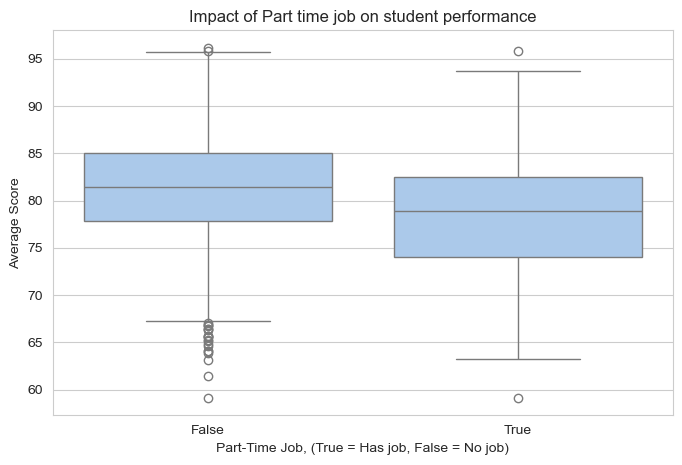

In [34]:
#Plotting the visual for the impact of part time job on student performance
plt.figure(figsize =(8,5))
sns.boxplot(x = student_scores["part_time_job"], y = student_scores["average_score"])

plt.xlabel("Part-Time Job, (True = Has job, False = No job)")
plt.ylabel("Average Score")
plt.title("Impact of Part time job on student performance")
plt.savefig("job")
plt.show()

Key Observations
On average, students who do not work tend to perform slightly better academically.

Even thought the overall score range for both groups is similar, with scores spanning from about 60 to 95, however, students without a job 
scores are less spread out and more consistent. which is the opposite for student with job, some do well, while others struggle.

Students without a part-time job tend to have slightly higher and more consistent scores compared to those with a job,
whose scores show greater variability. While working students may face time management challenges, some still perform well, 
suggesting that individual study habits play a key role. The impact of a job on performance is not drastic, but effective study 
strategies can help minimize any negative effects

## 3. Is there a relationship between absence days and lower academic performance?


In [35]:
student_without_absencedays = student_scores.loc[student_scores["absence_days"] < 2, ["email", "average_score"]]
student_without_absencedays.head()

,email,average_score
11,clinton.randolph.12@gslingacademy.com,74.000000
18,jonathan.werner.19@gslingacademy.com,91.428571
27,peter.gibbs.28@gslingacademy.com,81.857143
28,jeffrey.blanchard.29@gslingacademy.com,78.571429
30,angie.miller.31@gslingacademy.com,84.142857


In [36]:
#defining students with lower grades without absence days
lower_achiever = student_without_absencedays[student_without_absencedays["average_score"] < 70]

#defining the percentage of students with higher grades without absence days
percentage_lower_achiever = (len (lower_achiever)/len(student_without_absencedays)) * 100

print(f'percentage of student without absence days with an average score < 70 : {percentage_lower_achiever:.2f}%')

percentage of student without absence days with an average score < 70 : 1.94%


In [37]:
student_with_absencedays = student_scores.loc[student_scores["absence_days"] > 0, ["email", "average_score"]]
student_with_absencedays.head()

,email,average_score
0,paul.casey.1@gslingacademy.com,82.000000
1,danielle.sandoval.2@gslingacademy.com,91.428571
2,tina.andrews.3@gslingacademy.com,86.428571
3,tara.clark.4@gslingacademy.com,78.714286
4,anthony.campos.5@gslingacademy.com,74.428571


In [38]:
#defining students with lower grades with absence days
lower_achiever = student_with_absencedays[student_with_absencedays["average_score"] < 70]

#defining the percentage of students with higher grades without absence days
percentage_lower_achiever = (len (lower_achiever)/len(student_with_absencedays)) * 100

print(f'percentage of student with absence days with an average score < 70 : {percentage_lower_achiever:.2f}%')

percentage of student with absence days with an average score < 70 : 4.58%


In [39]:

# Group students by absence days and compute average score
absence_groups = student_scores.groupby("absence_days")["average_score"].mean().reset_index()

# Display
print(absence_groups)


    absence_days  average_score
0              0      81.616725
1              1      81.673230
2              2      82.112126
3              3      82.315051
4              4      81.078248
5              5      81.360058
6              6      78.924370
7              7      79.296703
8              8      78.745098
9              9      76.451531
10            10      76.660714


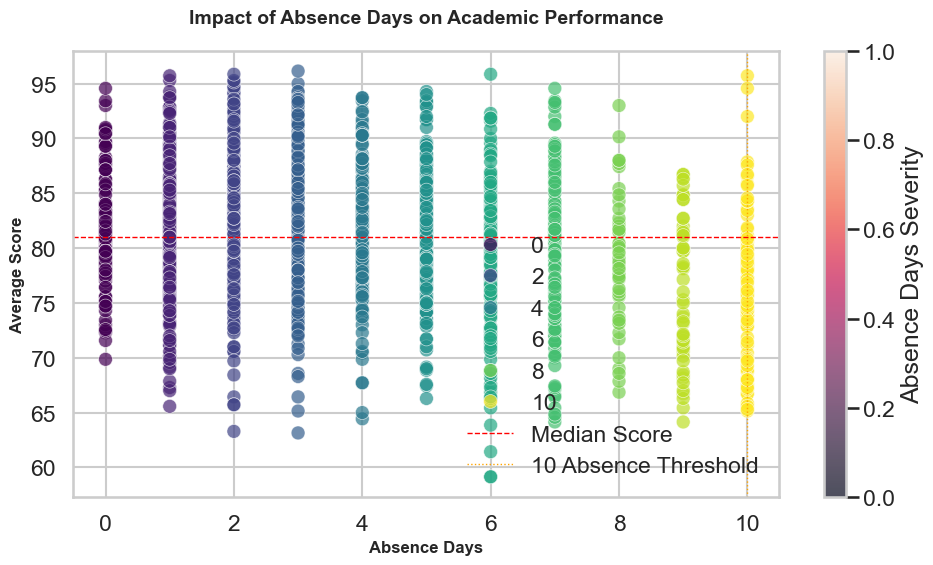

In [69]:

# Set style and context for presentation
sns.set_style("whitegrid")
sns.set_context("talk")  # Larger fonts for presentations
plt.figure(figsize=(10, 6))

# Create colorful scatterplot with enhanced styling
scatter = sns.scatterplot(
    x=student_scores["absence_days"], 
    y=student_scores["average_score"],
    hue=student_scores["absence_days"],  # Color by absence days
    palette="viridis",  # Colorful gradient
    alpha=0.7,
    s=100,  # Larger points
    edgecolor="w",  # White edges for better visibility
    linewidth=0.5
)

# Add annotations and styling
plt.xlabel("Absence Days", fontweight='bold', fontsize=12)
plt.ylabel("Average Score", fontweight='bold', fontsize=12)
plt.title("Impact of Absence Days on Academic Performance", 
          fontweight='bold', fontsize=14, pad=20)

# Add reference lines and annotations
plt.axhline(y=student_scores["average_score"].median(), 
            color='red', 
            linestyle='--', 
            linewidth=1,
            label='Median Score')
plt.axvline(x=10, 
            color='orange', 
            linestyle=':', 
            linewidth=1,
            label='10 Absence Threshold')

# Add legend and improve colorbar
plt.legend()
scatter.figure.colorbar(scatter.collections[0], label='Absence Days Severity')

# Adjust layout and save high-quality image
plt.tight_layout()
plt.savefig("absence_impact.png", dpi=300, bbox_inches='tight', transparent=False)
plt.show()

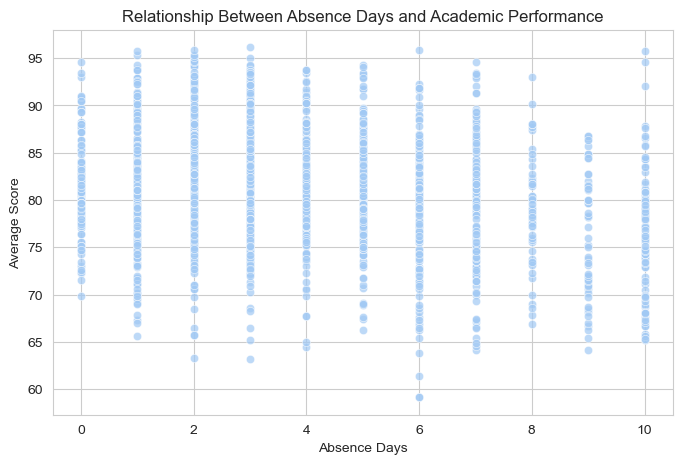

In [40]:
#visualizing the relationship between absence days and academic performance
plt.figure(figsize=(8,5))
sns.scatterplot(x=student_scores["absence_days"], y=student_scores["average_score"], alpha=0.7)
plt.xlabel("Absence Days")
plt.ylabel("Average Score")
plt.title("Relationship Between Absence Days and Academic Performance")
plt.savefig("absence days")
plt.show()


Key Observations

The points seem fairly spread out, suggesting no strong linear correlation between absence days and academic performance.

If there is a trend, it appears that students with fewer absences generally have higher scores, but there are still students with high scores even with more absences.

There are a few cases where students with high absence days (e.g., 9-10) still have high scores.

Similarly, some students with low absence days (0-2) have relatively low scores.

Possible Insights:
Absenteeism may not be the sole factor affecting student performance. Other factors like study habits, intelligence, or teaching quality could also be at play.

## 4. Do extracurricular activities help or hurt student performance?

In [41]:
student_with_extra_activities =student_scores.loc[student_scores["extracurricular_activities"] == True, ["email", "average_score"]]
student_with_extra_activities.head()

,email,average_score
2,tina.andrews.3@gslingacademy.com,86.428571
6,anthony.smith.7@gslingacademy.com,84.714286
7,george.short.8@gslingacademy.com,82.000000
9,audrey.simpson.10@gslingacademy.com,76.714286
16,vicki.thompson.17@gslingacademy.com,83.000000


In [42]:
student_without_extra_activities =student_scores.loc[student_scores["extracurricular_activities"] == False, ["email", "average_score"]]
student_without_extra_activities.head()

,email,average_score
0,paul.casey.1@gslingacademy.com,82.000000
1,danielle.sandoval.2@gslingacademy.com,91.428571
3,tara.clark.4@gslingacademy.com,78.714286
4,anthony.campos.5@gslingacademy.com,74.428571
5,kelly.wade.6@gslingacademy.com,82.000000


In [43]:
#checking the mean of the average score os student with and without extracurricular_activities
avg_score_with_extracurricular_activities = student_scores[student_scores["extracurricular_activities"] == True]["average_score"].mean()
avg_score_without_extracurricular_activities = student_scores[student_scores["extracurricular_activities"] == False]["average_score"].mean()

print(f"Average Score (With extracurricular activities): {avg_score_with_extracurricular_activities:.2f}")
print(f"Average Score (Without extracurricular activities): {avg_score_without_extracurricular_activities:.2f}")

Average Score (With extracurricular activities): 80.60
Average Score (Without extracurricular activities): 81.08


C:\Users\baliq\AppData\Local\Temp\ipykernel_19156\3949902961.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  boxplot = sns.boxplot(


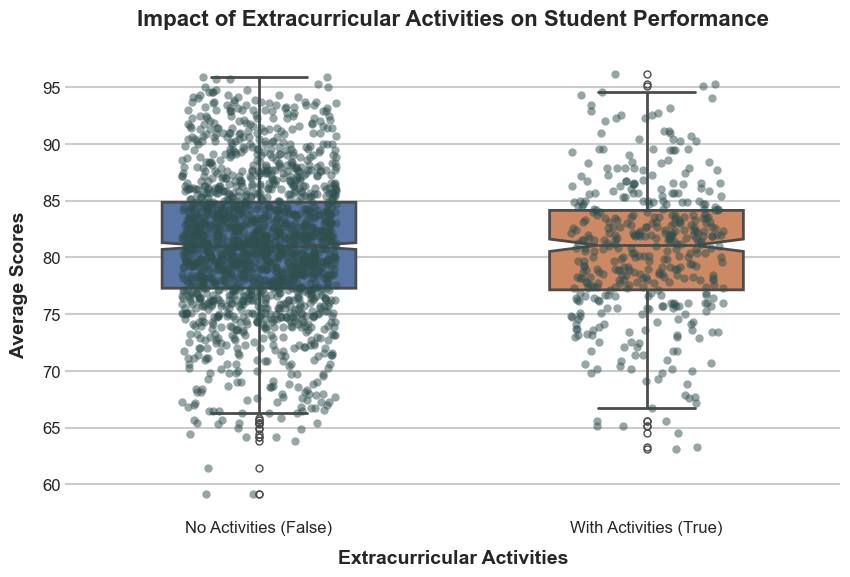

In [80]:

# Set style and color palette
sns.set_style("whitegrid")
palette = ["#4C72B0", "#DD8452"]  # Blue and orange colors

# Create figure with larger size for presentation
plt.figure(figsize=(10, 6), dpi=100)

# Create boxplot with enhanced styling
boxplot = sns.boxplot(
    x=student_scores["extracurricular_activities"], 
    y=student_scores["average_score"],
    palette=palette,
    width=0.5,
    linewidth=2,
    fliersize=5,
    notch=True
)

# Add stripplot for actual data points
stripplot = sns.stripplot(
    x=student_scores["extracurricular_activities"],
    y=student_scores["average_score"],
    color="#2F4F4F",  # Dark slate gray
    alpha=0.5,
    size=6,
    jitter=0.2
)

# Customize x-axis labels
plt.xticks(ticks=[0, 1], labels=["No Activities (False)", "With Activities (True)"], fontsize=12)
# Customize labels and title with larger fonts

plt.xlabel("Extracurricular Activities", fontsize=14, fontweight='bold', labelpad=10)
plt.ylabel("Average Scores", fontsize=14, fontweight='bold', labelpad=10)
plt.title("Impact of Extracurricular Activities on Student Performance", 
          fontsize=16, fontweight='bold', pad=20)

# Customize ticks
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# Add grid and adjust layout
#plt.grid(True, linestyle='--', alpha=0.7)
#plt.tight_layout()

# Save high-quality image for presentation (PNG and PDF)
plt.savefig("extracurricular_impact.png", dpi=300, bbox_inches='tight', transparent=False)
plt.savefig("extracurricular_impact.pdf", bbox_inches='tight')

plt.show()

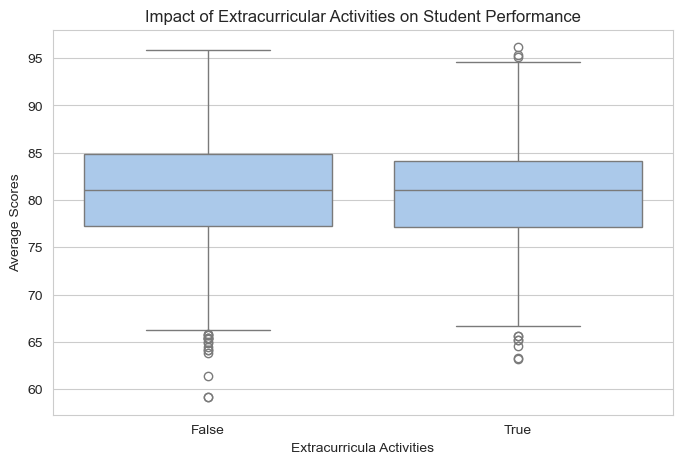

In [44]:
plt.figure(figsize=(8,5))
sns.boxplot(x = student_scores["extracurricular_activities"], y = student_scores["average_score"])

plt.xlabel("Extracurricula Activities")
plt.ylabel("Average Scores")
plt.title("Impact of Extracurricular Activities on Student Performance")
plt.savefig("extracurricula")
plt.show()

Just like the "absence days" effect, there are no strong evidence that extracurricular activities positively or negatively impact 
academic performance based on this dataset.

Both groups have similar median scores, spread, and outliers.

Other factors (e.g., study habits, class attendance, or personal discipline) might be more significant in determining student performance.

## 5. Which subject has the strongest correlation with overall academic success?


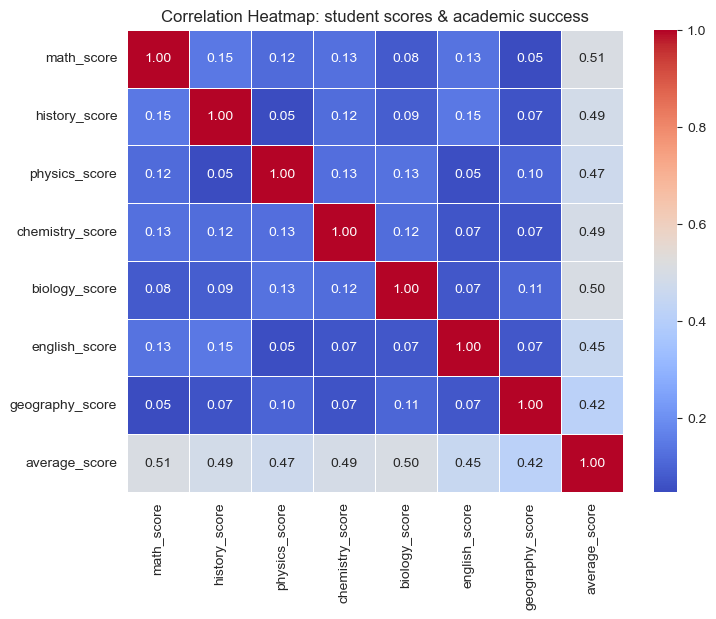

In [45]:
corr_matrix = student_scores[["math_score", "history_score","physics_score","chemistry_score","biology_score","english_score",
                                                    "geography_score","average_score"]].corr()

# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

plt.title("Correlation Heatmap: student scores & academic success")
plt.show()

In [46]:
subject_correlation = corr_matrix["average_score"].drop("average_score").sort_values(ascending=False)
print(subject_correlation)


math_score         0.508116
biology_score      0.502391
chemistry_score    0.492216
history_score      0.486900
physics_score      0.472104
english_score      0.451550
geography_score    0.415929
Name: average_score, dtype: float64


C:\Users\baliq\AppData\Local\Temp\ipykernel_19156\2897719100.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


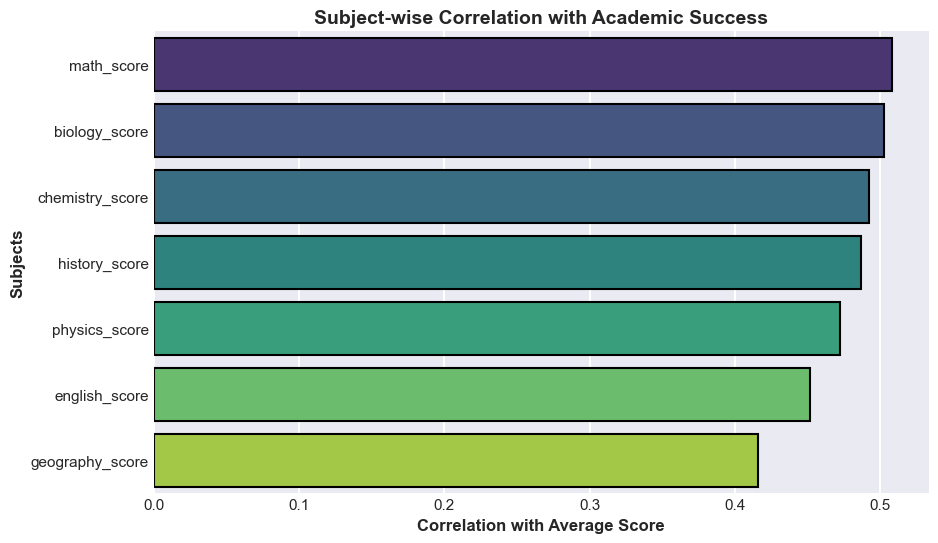

In [82]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a modern style
plt.style.use("seaborn-v0_8-darkgrid")

# Create the figure
plt.figure(figsize=(10, 6))

# Create a colorful horizontal bar plot
sns.barplot(
    x=subject_correlation.values,
    y=subject_correlation.index,
    palette="viridis",  # Using a vibrant and visually appealing colormap
    edgecolor="black"  # Adding black edges for better clarity
)

# Labels and title with improved formatting
plt.xlabel("Correlation with Average Score", fontsize=12, fontweight="bold")
plt.ylabel("Subjects", fontsize=12, fontweight="bold")
plt.title("Subject-wise Correlation with Academic Success", fontsize=14, fontweight="bold")

# Adjust layout for better visibility
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

# Save with high resolution for presentations
plt.savefig("subject_correlation_presentation.png", dpi=300, bbox_inches="tight")

# Show the plot
plt.show()


From these correlation results, Math has the strongest correlation (0.508) with overall academic success, 
followed closely by Biology (0.502) and Chemistry (0.492).

Math is the strongest predictor of academic success. Students who do well in Math tend to have higher overall performance.
Science subjects (Biology, Chemistry, and Physics) have strong correlations suggesting that strong STEM skills contribute to better academic performance.
Geography has the weakest correlation (0.416)—which may mean it has less impact on a student's overall academic success.

# General Recommendations:
By focusing on effective study methods, time management, attendance support, extracurricular balance, 
and STEM education, students can achieve better academic outcomes while maintaining a well-rounded experience
